# Import libraries and isntallation 

In [195]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

from xgboost import XGBRegressor

In [6]:
!pip install xgboost

In [219]:
# List of required files
files = [
    "data/train.csv",
    "data/features.csv",
    "data/stores.csv"
]

# Check whether all files exist
for file_path in files:
    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"ERROR: The file '{file_path}' does not exist. "
            "Please check the data folder and file name."
        )

print("All data files exist. Loading the files...")

# Load the data
train = pd.read_csv("data/train.csv")
features = pd.read_csv("data/features.csv")
stores = pd.read_csv("data/stores.csv")

print("All three data files loaded successfully!")

All data files exist. Loading the files...
All three data files loaded successfully!


# Inspecting data

In [197]:
print(train.shape)
print(features.shape)
print(stores.shape)

print(train.head())
print(features.head())
print(stores.head())
print(train.info())
print(train.describe())
train.isnull().sum()

(421570, 5)
(8190, 12)
(45, 3)
   Store  Dept       Date  Weekly_Sales  IsHoliday
0      1     1 2010-02-05      24924.50      False
1      1     1 2010-02-12      46039.49       True
2      1     1 2010-02-19      41595.55      False
3      1     1 2010-02-26      19403.54      False
4      1     1 2010-03-05      21827.90      False
   Store       Date  Temperature  Fuel_Price  MarkDown1  MarkDown2  MarkDown3  \
0      1 2010-02-05        42.31       2.572        NaN        NaN        NaN   
1      1 2010-02-12        38.51       2.548        NaN        NaN        NaN   
2      1 2010-02-19        39.93       2.514        NaN        NaN        NaN   
3      1 2010-02-26        46.63       2.561        NaN        NaN        NaN   
4      1 2010-03-05        46.50       2.625        NaN        NaN        NaN   

   MarkDown4  MarkDown5         CPI  Unemployment  IsHoliday  
0        NaN        NaN  211.096358         8.106      False  
1        NaN        NaN  211.242170         8.106 

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64

# Convert Data

In [198]:
train["Date"] = pd.to_datetime(train["Date"])
features["Date"] = pd.to_datetime(features["Date"])
print(train["Date"].min())
print(train["Date"].max())

2010-02-05 00:00:00
2012-10-26 00:00:00


# Merging dataset 

In [199]:
df = train.merge(
    features,
    on=["Store", "Date"],
    how="left",
    suffixes=("", "_feature")
)
df = df.merge(
    stores,
    on="Store",
    how="left"
)
display(train.head())
display(features.head())
display(df.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_feature,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


# Clean the data

In [200]:
markdown_cols = [
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5"
]

for col in markdown_cols:
    if col in df.columns:
        df[col] = df[col].fillna(0)
display(df.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_feature,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,False,A,151315


# Create calendar features

In [201]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
df["Quarter"] = df["Date"].dt.quarter

display(df.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,MarkDown5,CPI,Unemployment,IsHoliday_feature,Type,Size,Year,Month,Week,Quarter
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,0.0,211.096358,8.106,False,A,151315,2010,2,5,1
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,0.0,211.242170,8.106,True,A,151315,2010,2,6,1
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,0.0,211.289143,8.106,False,A,151315,2010,2,7,1
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,0.0,211.319643,8.106,False,A,151315,2010,2,8,1
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,0.0,211.350143,8.106,False,A,151315,2010,3,9,1


# Shorting data

In [202]:
df = df.sort_values(
    ["Store", "Dept", "Date"]
)

display(df.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,MarkDown5,CPI,Unemployment,IsHoliday_feature,Type,Size,Year,Month,Week,Quarter
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,0.0,211.096358,8.106,False,A,151315,2010,2,5,1
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,0.0,211.242170,8.106,True,A,151315,2010,2,6,1
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,0.0,211.289143,8.106,False,A,151315,2010,2,7,1
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,0.0,211.319643,8.106,False,A,151315,2010,2,8,1
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,0.0,211.350143,8.106,False,A,151315,2010,3,9,1


# creating lag features

In [203]:
group = df.groupby(["Store", "Dept"])["Weekly_Sales"]

df["lag_1"] = group.shift(1)
df["lag_2"] = group.shift(2)
df["lag_4"] = group.shift(4)
df["lag_52"] = group.shift(52)

display(df.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Type,Size,Year,Month,Week,Quarter,lag_1,lag_2,lag_4,lag_52
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,A,151315,2010,2,5,1,NaN,NaN,NaN,NaN
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,A,151315,2010,2,6,1,24924.50,NaN,NaN,NaN
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,A,151315,2010,2,7,1,46039.49,24924.50,NaN,NaN
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,A,151315,2010,2,8,1,41595.55,46039.49,NaN,NaN
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,A,151315,2010,3,9,1,19403.54,41595.55,24924.5,NaN


# Create rolling features

In [204]:
df["rolling_mean_4"] = (
    df.groupby(["Store", "Dept"])["Weekly_Sales"]
      .transform(lambda x: x.shift(1).rolling(4).mean())
)

df["rolling_std_4"] = (
    df.groupby(["Store", "Dept"])["Weekly_Sales"]
      .transform(lambda x: x.shift(1).rolling(4).std())
)
display(df.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,...,Year,Month,Week,Quarter,lag_1,lag_2,lag_4,lag_52,rolling_mean_4,rolling_std_4
0,1,1,2010-02-05,24924.50,False,42.31,2.572,0.0,0.0,0.0,...,2010,2,5,1,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1,2010-02-12,46039.49,True,38.51,2.548,0.0,0.0,0.0,...,2010,2,6,1,24924.50,NaN,NaN,NaN,NaN,NaN
2,1,1,2010-02-19,41595.55,False,39.93,2.514,0.0,0.0,0.0,...,2010,2,7,1,46039.49,24924.50,NaN,NaN,NaN,NaN
3,1,1,2010-02-26,19403.54,False,46.63,2.561,0.0,0.0,0.0,...,2010,2,8,1,41595.55,46039.49,NaN,NaN,NaN,NaN
4,1,1,2010-03-05,21827.90,False,46.50,2.625,0.0,0.0,0.0,...,2010,3,9,1,19403.54,41595.55,24924.5,NaN,32990.77,12832.106391


# Remove rows where lag information doesn't exist

In [146]:
model_df = df.dropna(
    subset=[
        "lag_1",
        "lag_2",
        "lag_4",
        "lag_52",
        "rolling_mean_4"
    ]
).copy()
print (model_df[["lag_1", "lag_2","lag_4","lag_52","rolling_mean_4"]].isnull().sum())

lag_1             0
lag_2             0
lag_4             0
lag_52            0
rolling_mean_4    0
dtype: int64


In [147]:
y = model_df["Weekly_Sales"]
feature_cols = [
    "Store",
    "Dept",
    "Year",
    "Month",
    "Week",
    "Quarter",
    "IsHoliday",
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_52",
    "rolling_mean_4",
    "rolling_std_4"
]
X = model_df[feature_cols].copy()

print (X.head())
print (y.head())

    Store  Dept  Year  Month  Week  Quarter  IsHoliday     lag_1     lag_2  \
52      1     1  2011      2     5        1      False  18461.18  17341.47   
53      1     1  2011      2     6        1       True  21665.76  18461.18   
54      1     1  2011      2     7        1      False  37887.17  21665.76   
55      1     1  2011      2     8        1      False  46845.87  37887.17   
56      1     1  2011      3     9        1      False  19363.83  46845.87   

       lag_4    lag_52  rolling_mean_4  rolling_std_4  
52  15984.24  24924.50      17286.6475    1013.925386  
53  17359.70  46039.49      18707.0275    2040.798674  
54  17341.47  41595.55      23838.8950    9543.110891  
55  18461.18  19403.54      31214.9950   13449.781394  
56  21665.76  21827.90      31440.6575   13169.111324  
52    21665.76
53    37887.17
54    46845.87
55    19363.83
56    20327.61
Name: Weekly_Sales, dtype: float64


# uniqe Dated data shorted 

In [205]:
unique_dates = np.sort(model_df["Date"].unique())

#veriable declearation as questioned asked 

n_splits = 6
test_size = 10
gap = 1

folds = []
n_dates = len(unique_dates)
print(n_dates)


folds = []

n_dates = len(unique_dates)

for i in range(n_splits):
    
    test_end = n_dates - (n_splits - 1 - i) * test_size
    test_start = test_end - test_size
    
    train_end = test_start - gap
    
    train_dates = unique_dates[:train_end]
    test_dates = unique_dates[test_start:test_end]
    
    folds.append((train_dates, test_dates))
print("Number of folds:", len(folds))
    

91
Number of folds: 6


In [206]:
for i, (train_dates, test_dates) in enumerate(folds, start=1):
    print(
        f"Fold {i}:",
        train_dates[0],
        "→",
        train_dates[-1],
        "| TEST:",
        test_dates[0],
        "→",
        test_dates[-1]
    )

Fold 1: 2011-02-04T00:00:00.000000 → 2011-08-26T00:00:00.000000 | TEST: 2011-09-09T00:00:00.000000 → 2011-11-11T00:00:00.000000
Fold 2: 2011-02-04T00:00:00.000000 → 2011-11-04T00:00:00.000000 | TEST: 2011-11-18T00:00:00.000000 → 2012-01-20T00:00:00.000000
Fold 3: 2011-02-04T00:00:00.000000 → 2012-01-13T00:00:00.000000 | TEST: 2012-01-27T00:00:00.000000 → 2012-03-30T00:00:00.000000
Fold 4: 2011-02-04T00:00:00.000000 → 2012-03-23T00:00:00.000000 | TEST: 2012-04-06T00:00:00.000000 → 2012-06-08T00:00:00.000000
Fold 5: 2011-02-04T00:00:00.000000 → 2012-06-01T00:00:00.000000 | TEST: 2012-06-15T00:00:00.000000 → 2012-08-17T00:00:00.000000
Fold 6: 2011-02-04T00:00:00.000000 → 2012-08-10T00:00:00.000000 | TEST: 2012-08-24T00:00:00.000000 → 2012-10-26T00:00:00.000000


In [101]:
train_dates, test_dates = folds[0]

train_data = model_df[model_df["Date"].isin(train_dates)].copy()

test_data = model_df[model_df["Date"].isin(test_dates)].copy()

print(train_data.shape, test_data.shape)

(84466, 27) (28741, 27)


# Naive baseline

In [207]:
def naive_forecast(test_df):
    return test_df["lag_1"].values

# Linear Regression

In [208]:
linear_model = LinearRegression()

linear_model.fit(
    train_data[feature_cols],
    train_data["Weekly_Sales"]
)

#Prediction:

pred_linear = linear_model.predict(
    test_data[feature_cols]
)
print(pred_linear)

[15952.52383351 16350.98050603 18670.79880117 ...  1532.50752228
  1591.62937302  1607.21543469]


# XGBoost

In [209]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

xgb_model.fit(
    train_data[feature_cols],
    train_data["Weekly_Sales"]
)

pred_xgb = xgb_model.predict(
    test_data[feature_cols]
)

print(pred_xgb)

[16294.32    16381.878   18026.545   ...   567.9161    955.8696
   817.58984]


# MODEL-EVALUATION


In [210]:

results = []

for fold_number, (train_dates, test_dates) in enumerate(folds, start=1):

    train_data = model_df[
        model_df["Date"].isin(train_dates)
    ].copy()

    test_data = model_df[
        model_df["Date"].isin(test_dates)
    ].copy()

    print(f"\nFold {fold_number}")

    print(
        "Train:",
        train_data["Date"].min(),
        "→",
        train_data["Date"].max()
    )

    print(
        "Test:",
        test_data["Date"].min(),
        "→",
        test_data["Date"].max()
    )

    actual = test_data["Weekly_Sales"].values

    # -------------------------
    # MASE SCALE
    # Calculate from training data
    # -------------------------

    mase_scale = (
        train_data["Weekly_Sales"] - train_data["lag_1"]
    ).abs().mean()

    if pd.isna(mase_scale) or mase_scale == 0:
        raise ValueError(
            f"Invalid MASE scale in fold {fold_number}"
        )

    # -------------------------
    # 1. NAIVE BASELINE
    # -------------------------

    pred_naive = test_data["lag_1"].values

    naive_mae = mean_absolute_error(
        actual,
        pred_naive
    )

    naive_rmse = mean_squared_error(
        actual,
        pred_naive
    ) ** 0.5

    results.append({
        "fold": fold_number,
        "model": "Naive",
        "MAE": naive_mae,
        "RMSE": naive_rmse,
        "MASE": naive_mae / mase_scale
    })

    # -------------------------
    # 2. LINEAR REGRESSION
    # -------------------------

    linear_model = LinearRegression()

    linear_model.fit(
        train_data[feature_cols],
        train_data["Weekly_Sales"]
    )

    pred_linear = linear_model.predict(
        test_data[feature_cols]
    )

    linear_mae = mean_absolute_error(
        actual,
        pred_linear
    )

    linear_rmse = mean_squared_error(
        actual,
        pred_linear
    ) ** 0.5

    results.append({
        "fold": fold_number,
        "model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "MASE": linear_mae / mase_scale
    })

    # -------------------------
    # 3. XGBOOST
    # -------------------------

    xgb_model = XGBRegressor(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    )

    xgb_model.fit(
        train_data[feature_cols],
        train_data["Weekly_Sales"]
    )

    pred_xgb = xgb_model.predict(
        test_data[feature_cols]
    )

    xgb_mae = mean_absolute_error(
        actual,
        pred_xgb
    )

    xgb_rmse = mean_squared_error(
        actual,
        pred_xgb
    ) ** 0.5

    results.append({
        "fold": fold_number,
        "model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "MASE": xgb_mae / mase_scale
    })


# -------------------------
# CREATE RESULTS TABLE
# -------------------------

results_df = pd.DataFrame(results)

print("\nNumber of folds:", len(folds))
print("Number of result rows:", len(results_df))

display(results_df)

# Save the per-fold results
results_df.to_csv(
    "results_per_fold.csv",
    index=False
)




Fold 1
Train: 2011-02-04 00:00:00 → 2011-08-26 00:00:00
Test: 2011-09-09 00:00:00 → 2011-11-11 00:00:00

Fold 2
Train: 2011-02-04 00:00:00 → 2011-11-04 00:00:00
Test: 2011-11-18 00:00:00 → 2012-01-20 00:00:00

Fold 3
Train: 2011-02-04 00:00:00 → 2012-01-13 00:00:00
Test: 2012-01-27 00:00:00 → 2012-03-30 00:00:00

Fold 4
Train: 2011-02-04 00:00:00 → 2012-03-23 00:00:00
Test: 2012-04-06 00:00:00 → 2012-06-08 00:00:00

Fold 5
Train: 2011-02-04 00:00:00 → 2012-06-01 00:00:00
Test: 2012-06-15 00:00:00 → 2012-08-17 00:00:00

Fold 6
Train: 2011-02-04 00:00:00 → 2012-08-10 00:00:00
Test: 2012-08-24 00:00:00 → 2012-10-26 00:00:00

Number of folds: 6
Number of result rows: 18


,fold,model,MAE,RMSE,MASE
0,1,Naive,1712.755157,3967.546193,1.019587
1,1,Linear Regression,1424.542898,3098.546736,0.848017
2,1,XGBoost,1434.915964,3241.465183,0.854192
3,2,Naive,4773.927795,16006.155477,2.821577
4,2,Linear Regression,2957.229690,8657.096638,1.747838
5,2,XGBoost,3214.453848,10108.773333,1.899867
6,3,Naive,1768.502439,3893.240128,0.754360
7,3,Linear Regression,1551.195584,3386.281703,0.661667
8,3,XGBoost,1430.758082,3100.632118,0.610294
9,4,Naive,1928.066170,4419.104854,0.860195


# Reasult

In [211]:
    results_df = pd.DataFrame(results)

    results_df

,fold,model,MAE,RMSE,MASE
0,1,Naive,1712.755157,3967.546193,1.019587
1,1,Linear Regression,1424.542898,3098.546736,0.848017
2,1,XGBoost,1434.915964,3241.465183,0.854192
3,2,Naive,4773.927795,16006.155477,2.821577
4,2,Linear Regression,2957.229690,8657.096638,1.747838
5,2,XGBoost,3214.453848,10108.773333,1.899867
6,3,Naive,1768.502439,3893.240128,0.754360
7,3,Linear Regression,1551.195584,3386.281703,0.661667
8,3,XGBoost,1430.758082,3100.632118,0.610294
9,4,Naive,1928.066170,4419.104854,0.860195


In [212]:

summary = (
    results_df
    .groupby("model")[["MAE", "RMSE", "MASE"]]
    .agg(["mean", "std"])
)

display(summary)

summary.to_csv("summary_mean_std.csv")

MAE                      RMSE               \
                          mean          std         mean          std   
model                                                                   
Linear Regression  1792.092709   582.227277  4160.685638  2237.529948   
Naive              2213.964867  1262.255855  5866.600981  4981.037213   
XGBoost            1703.676942   750.757728  4249.131278  2903.855012   

                       MASE            
                       mean       std  
model                                  
Linear Regression  0.911046  0.415619  
Naive              1.149696  0.827073  
XGBoost            0.876814  0.511690

# Figure #1

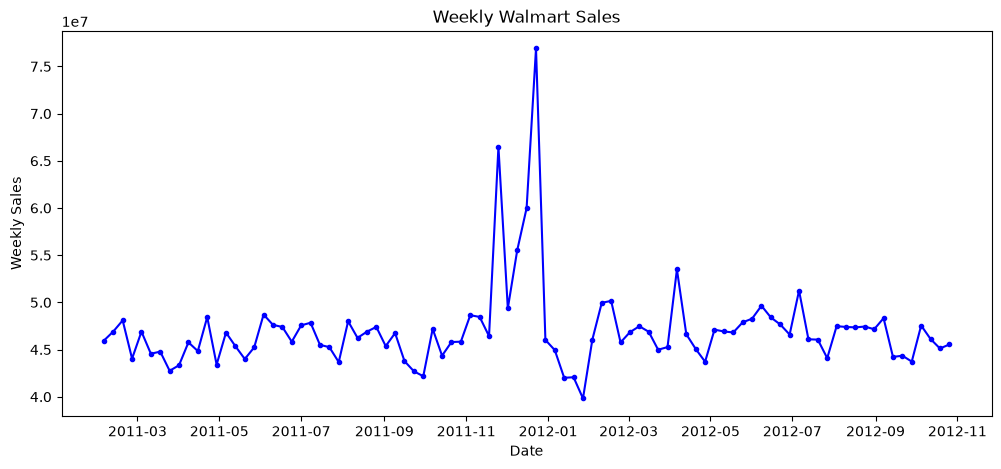

In [213]:
weekly_sales = (
    model_df
    .groupby("Date")["Weekly_Sales"]
    .sum()
)

plt.figure(figsize=(12,5))

plt.plot(
    weekly_sales.index,
    weekly_sales.values,color="b",marker="."
)

plt.title(
    "Weekly Walmart Sales"
)

plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.show()

# Figure #2

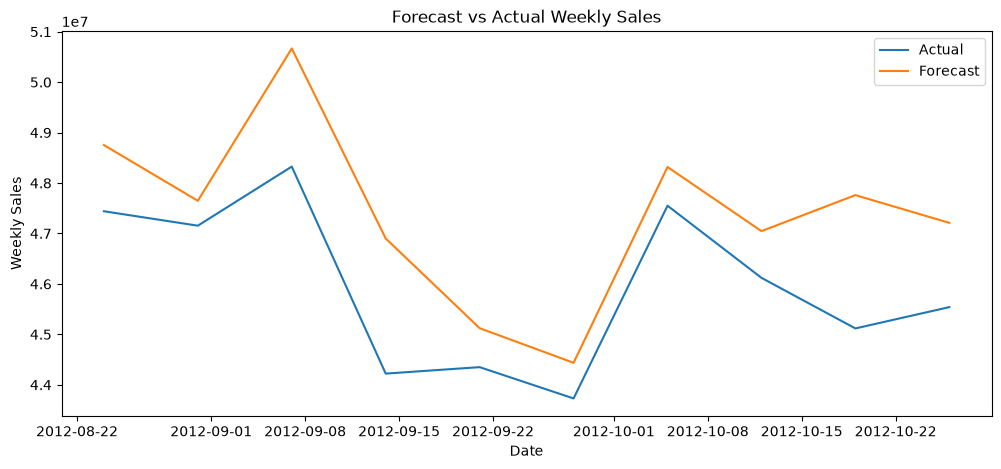

In [214]:
last_train_dates, last_test_dates = folds[-1]

test_last = model_df[
    model_df["Date"].isin(last_test_dates)
].copy()

# train 

final_model = LinearRegression()

final_model.fit(
    model_df[
        model_df["Date"].isin(last_train_dates)
    ][feature_cols],
    model_df[
        model_df["Date"].isin(last_train_dates)
    ]["Weekly_Sales"]
)

# pridict 

forecast = final_model.predict(
    test_last[feature_cols]
)

# actual and forcust 

plot_data = test_last[
    ["Date", "Weekly_Sales"]
].copy()

plot_data["Forecast"] = forecast

plot_data = (
    plot_data
    .groupby("Date")[["Weekly_Sales", "Forecast"]]
    .sum()
)

# visualizing in graph 

plt.figure(figsize=(12,5))

plt.plot(
    plot_data.index,
    plot_data["Weekly_Sales"],
    label="Actual"
)

plt.plot(
    plot_data.index,
    plot_data["Forecast"],
    label="Forecast"
)

plt.title(
    "Forecast vs Actual Weekly Sales"
)

plt.xlabel("Date")
plt.ylabel("Weekly Sales")

plt.legend()

plt.show()

# Figure 3

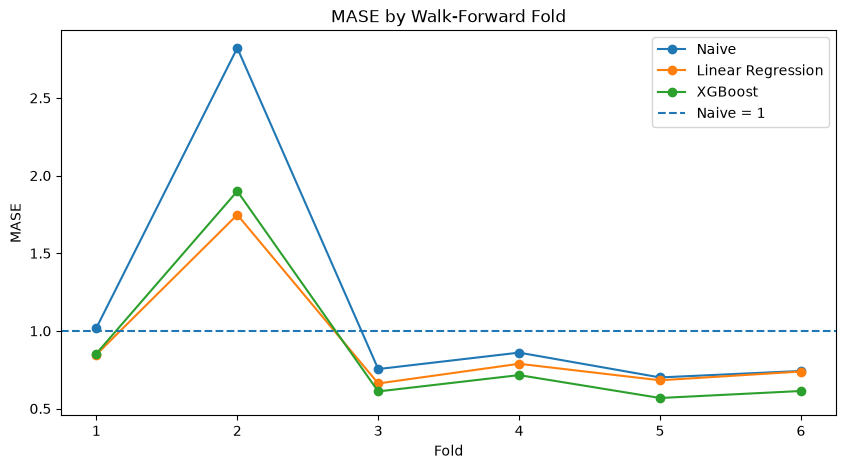

In [215]:
plt.figure(figsize=(10,5))

for model in results_df["model"].unique():

    temp = results_df[
        results_df["model"] == model
    ]

    plt.plot(
        temp["fold"],
        temp["MASE"],
        marker="o",
        label=model
    )

plt.axhline(
    1,
    linestyle="--",
    label="Naive = 1"
)

plt.title(
    "MASE by Walk-Forward Fold"
)

plt.xlabel("Fold")
plt.ylabel("MASE")

plt.legend()

plt.show()

# Figure 4

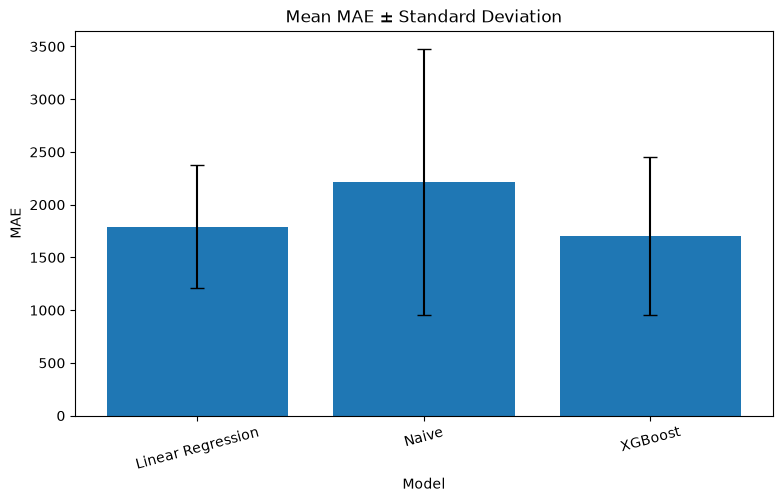

In [216]:
mean_mae = (
    results_df
    .groupby("model")["MAE"]
    .mean()
)

std_mae = (
    results_df
    .groupby("model")["MAE"]
    .std()
)

plt.figure(figsize=(9,5))

plt.bar(
    mean_mae.index,
    mean_mae.values,
    yerr=std_mae.values,
    capsize=5
)

plt.title(
    "Mean MAE ± Standard Deviation"
)

plt.xlabel("Model")
plt.ylabel("MAE")

plt.xticks(rotation=15)

plt.show()

# saving 

In [218]:
# Save results_per_fold.csv
file_path = "results_per_fold.csv"

if os.path.exists(file_path):
    print("results_per_fold.csv already exists. Replacing the old file...")
else:
    print("results_per_fold.csv does not exist. Creating a new file...")

results_df.to_csv(file_path, index=False)

print("results_per_fold.csv saved successfully!")


#Save summary_mean_std.csv
file_path = "summary_mean_std.csv"

if os.path.exists(file_path):
    print("summary_mean_std.csv already exists. Replacing the old file...")
else:
    print("summary_mean_std.csv does not exist. Creating a new file...")

summary.to_csv(file_path)

print("summary_mean_std.csv saved successfully!")

results_per_fold.csv already exists. Replacing the old file...
results_per_fold.csv saved successfully!
summary_mean_std.csv already exists. Replacing the old file...
summary_mean_std.csv saved successfully!
